# Agrupación de casas con K-Means

Proyecto del módulo «Modelos de clasificación» de 4Geeks (*Proyecto Tutorial K-Medias*).

Objetivos del enunciado:

- Comprender un dataset nuevo.
- Modelar los datos con un K-Means.
- Analizar los resultados y entrenar un modelo supervisado.

Queremos agrupar las casas de California por su región (`Latitude`, `Longitude`) y su ingreso medio (`MedInc`). El dataset es *California Housing*, construido con el censo de 1990: cada fila es un grupo de bloques censales, la unidad geográfica más pequeña para la que se publican datos. `MedInc` es la mediana de ingresos del grupo en decenas de miles de dólares.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
N_CLUSTERS = 6
FEATURES = ["Latitude", "Longitude", "MedInc"]

ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW = ROOT / "data" / "raw" / "housing.csv"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
URL = "https://raw.githubusercontent.com/4GeeksAcademy/k-means-project-tutorial/main/housing.csv"

## Paso 1: carga del conjunto de datos

El enunciado permite leerlo desde el enlace o guardarlo a mano en el repositorio. Hacemos las dos cosas: si `data/raw/housing.csv` no existe, lo descargamos del enlace y lo guardamos ahí.

In [2]:
if not RAW.exists():
    pd.read_csv(URL).to_csv(RAW, index=False)

housing = pd.read_csv(RAW)
print(housing.shape)
housing.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Solo nos interesan `Latitude`, `Longitude` y `MedInc`.

In [3]:
df = housing[FEATURES].copy()
print("nulos:", int(df.isna().sum().sum()), "| filas duplicadas:", int(df.duplicated().sum()))
df.describe().round(2)

nulos: 0 | filas duplicadas: 5


,Latitude,Longitude,MedInc
count,20640.00,20640.00,20640.00
mean,35.63,-119.57,3.87
std,2.14,2.00,1.90
min,32.54,-124.35,0.50
25%,33.93,-121.80,2.56
50%,34.26,-118.49,3.53
75%,37.71,-118.01,4.74
max,41.95,-114.31,15.00


No hay nulos. Las 5 filas duplicadas son grupos de bloques distintos con las mismas coordenadas redondeadas y el mismo ingreso, así que las dejamos.

**Escala.** K-Means agrupa por distancia euclídea, así que una variable con más dispersión pesaría más. Aquí las tres tienen una desviación típica muy parecida (2,1 grados de latitud, 2,0 de longitud y 1,9 decenas de miles de dólares). Usamos los valores originales sin escalar: los grupos son los mismos en la práctica y los centroides se leen directamente en grados y en dólares.

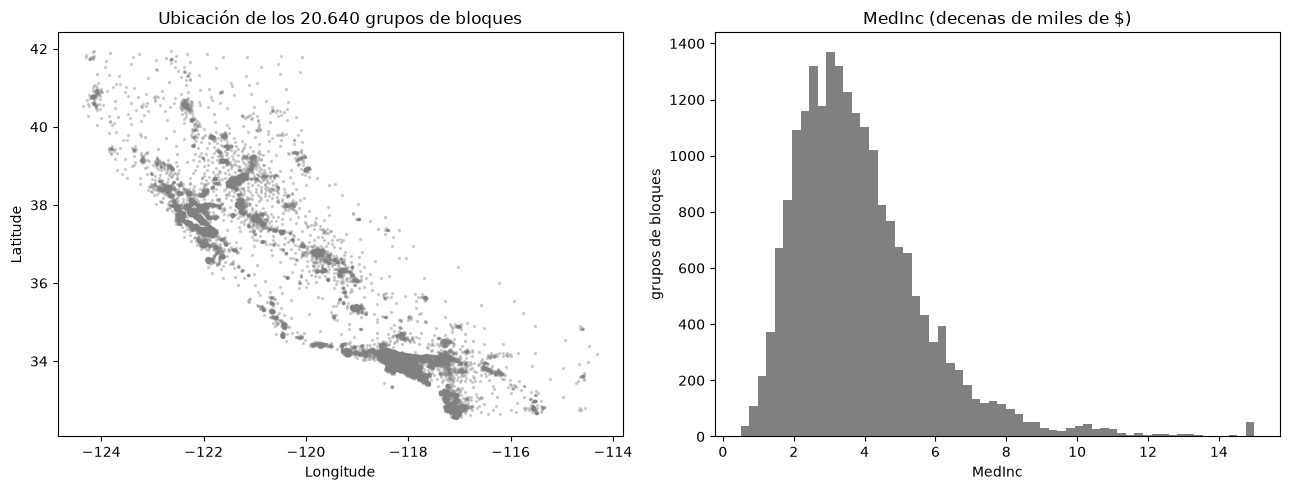

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df["Longitude"], df["Latitude"], s=2, alpha=0.3, color="gray")
axes[0].set(title="Ubicación de los 20.640 grupos de bloques", xlabel="Longitude", ylabel="Latitude")
axes[1].hist(df["MedInc"], bins=60, color="gray")
axes[1].set(title="MedInc (decenas de miles de $)", xlabel="MedInc", ylabel="grupos de bloques")
plt.tight_layout()
plt.show()

El mapa dibuja la forma de California, con dos grandes manchas: la bahía de San Francisco con Sacramento al norte, y Los Ángeles con San Diego al sur. El ingreso tiene cola a la derecha y un tope en 15: el censo recortó los valores altos.

Dividimos en train (80 %) y test (20 %). El K-Means se entrena solo con train; el test hace de casas nuevas a las que hay que asignar un cluster.

In [5]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=SEED)
X_train, X_test = X_train.copy(), X_test.copy()
print("train:", X_train.shape, "| test:", X_test.shape)

train: (16512, 3) | test: (4128, 3)


## Paso 2: construcción del K-Means

Seis clusters, como pide el enunciado. `n_init=10` repite el algoritmo con 10 inicializaciones y se queda con la de menor inercia, y la semilla fija hace que el resultado sea reproducible.

In [6]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
kmeans.fit(X_train)

labels = kmeans.labels_
print(type(labels), labels.dtype, np.unique(labels))

<class 'numpy.ndarray'> int32 [0 1 2 3 4 5]


K-Means devuelve un array de enteros del 0 al 5. Esos números son identificadores, no cantidades: el cluster 4 no es «el doble» que el 2. Por eso la columna `cluster` se guarda como categórica. Así pandas y seaborn la tratan como una etiqueta, con su propio color por grupo y sin medias ni escalas de color continuas.

In [7]:
X_train["cluster"] = pd.Categorical(labels)
print(X_train["cluster"].dtype)
X_train.head()

category


,Latitude,Longitude,MedInc,cluster
14196,32.71,-117.03,3.2596,2
8267,33.77,-118.16,3.8125,2
17445,34.66,-120.48,4.1563,0
14265,32.69,-117.11,1.9425,2
2271,36.78,-119.80,3.5542,0


In [8]:
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES).round(2)
summary = (X_train.groupby("cluster", observed=True)
           .agg(casas=("MedInc", "size"), lat=("Latitude", "mean"), lon=("Longitude", "mean"),
                medinc_media=("MedInc", "mean"), medinc_min=("MedInc", "min"), medinc_max=("MedInc", "max"))
           .round(2))
summary["%"] = (summary["casas"] / len(X_train) * 100).round(1)
summary

,casas,lat,lon,medinc_media,medinc_min,medinc_max,%
cluster,,,,,,,
0,1348,36.06,-119.72,2.69,0.50,5.39,8.2
1,342,35.17,-119.52,11.12,8.27,15.00,2.1
2,5628,33.82,-117.83,2.89,0.50,4.35,34.1
3,3024,33.86,-118.02,5.59,4.17,8.86,18.3
4,3919,38.35,-121.89,2.83,0.50,4.56,23.7
5,2251,37.70,-121.96,5.51,3.92,9.56,13.6


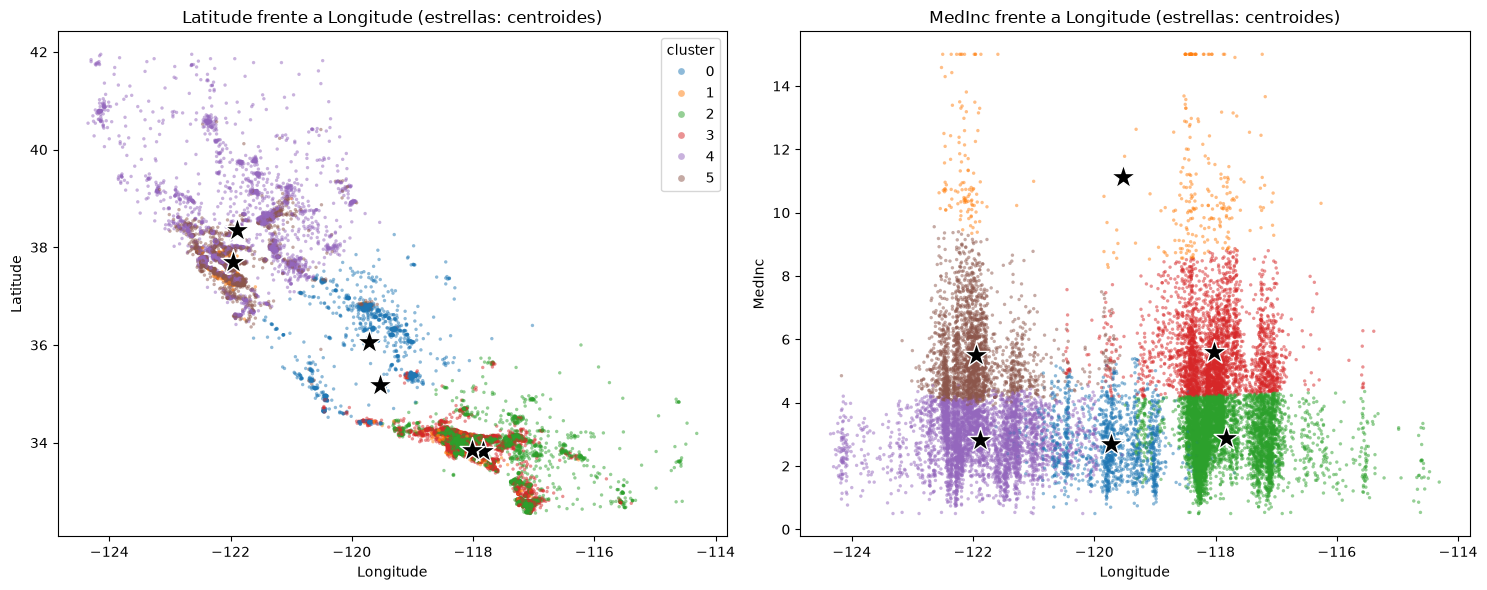

In [9]:
PALETTE = dict(zip(range(N_CLUSTERS), sns.color_palette("tab10", N_CLUSTERS)))

def plot_clusters(train, test=None):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    pairs = [("Longitude", "Latitude"), ("Longitude", "MedInc")]
    for ax, (x, y) in zip(axes, pairs):
        sns.scatterplot(data=train, x=x, y=y, hue="cluster", palette=PALETTE, s=6, alpha=0.5,
                        linewidth=0, ax=ax, legend=ax is axes[0])
        if test is not None:
            sns.scatterplot(data=test, x=x, y=y, hue="cluster", palette=PALETTE, s=16, marker="X",
                            edgecolor="black", linewidth=0.4, ax=ax, legend=False)
        ax.scatter(kmeans.cluster_centers_[:, FEATURES.index(x)], kmeans.cluster_centers_[:, FEATURES.index(y)],
                   marker="*", s=350, c="black", edgecolor="white")
        ax.set_title(f"{y} frente a {x} (estrellas: centroides)")
    axes[0].legend(title="cluster", markerscale=2, loc="upper right")
    plt.tight_layout()
    plt.show()

plot_clusters(X_train)

**Qué se ve.** K-Means ha dividido California en tres franjas de norte a sur y ha partido cada una por el ingreso. Además ha formado un sexto grupo solo con los ingresos más altos:

| Cluster | Zona | Ingreso medio (MedInc) | Casas de train |
| --- | --- | --- | --- |
| 4 | Norte: Sacramento, norte rural y parte de la bahía de San Francisco | bajo (2,8) | 23,7 % |
| 5 | Norte: bahía de San Francisco | medio-alto (5,5) | 13,6 % |
| 0 | Centro: Valle Central (Fresno, Bakersfield) y costa central | bajo (2,7) | 8,2 % |
| 2 | Sur: Los Ángeles, San Diego e interior | bajo (2,9) | 34,1 % |
| 3 | Sur: Los Ángeles y San Diego | medio-alto (5,6) | 18,3 % |
| 1 | Todo el estado, sobre todo la bahía y Los Ángeles | muy alto (11,1; mínimo 8,3) | 2,1 % |

- En el mapa (izquierda), los clusters 4 y 5 se superponen en la bahía, igual que el 2 y el 3 en Los Ángeles: dentro de una misma región, lo que los separa es el ingreso. El gráfico de la derecha lo muestra como un corte horizontal alrededor de `MedInc` ≈ 4 en cada zona.
- El cluster 1 junta las casas de ingresos más altos del norte y del sur. Su centroide (estrella aislada en latitud 35,2) cae en mitad del estado, donde casi no hay casas, porque es la media de dos zonas lejanas. En ese tramo de ingresos K-Means da más peso a la distancia en `MedInc` que a la ubicación.
- Los grupos están muy desequilibrados: el 2 tiene 16 veces más casas que el 1.

## Paso 3: predicción con el conjunto de test

`kmeans.predict` asigna cada casa de test al centroide más cercano. Las añadimos al gráfico anterior con una cruz del color de su cluster.

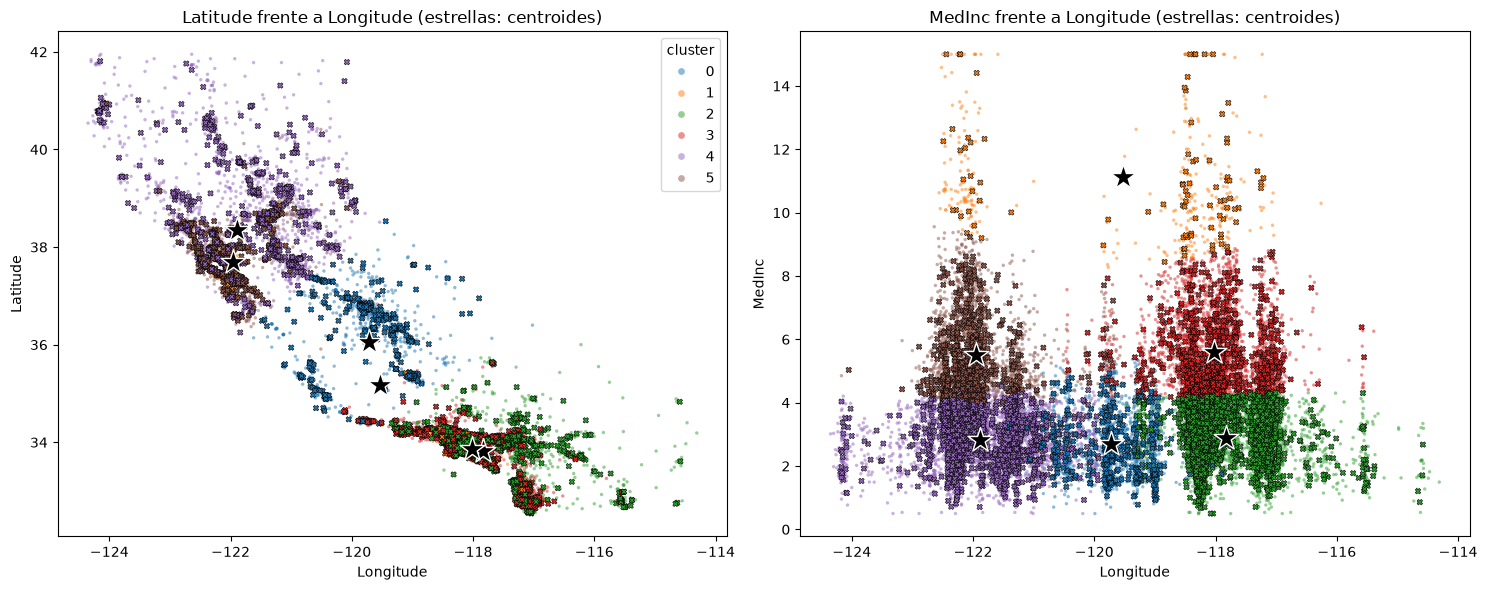

In [10]:
X_test["cluster"] = pd.Categorical(kmeans.predict(X_test[FEATURES]), categories=X_train["cluster"].cat.categories)
plot_clusters(X_train, X_test)

Para confirmar que la predicción es buena no basta con mirar el gráfico. Comprobamos tres cosas:

1. Que el reparto de casas entre clusters en test se parece al de train.
2. Que las medias de cada cluster en test coinciden con las de train.
3. Que la distancia de cada casa de test a su centroide es parecida a la de las casas de train.

In [11]:
def profile(data):
    return data.groupby("cluster", observed=True).agg(
        pct=("MedInc", lambda s: round(len(s) / len(data) * 100, 1)),
        lat=("Latitude", "mean"), lon=("Longitude", "mean"), medinc=("MedInc", "mean")).round(2)

comparison = profile(X_train).add_suffix("_train").join(profile(X_test).add_suffix("_test"))
comparison

,pct_train,lat_train,lon_train,medinc_train,pct_test,lat_test,lon_test,medinc_test
cluster,,,,,,,,
0,8.2,36.06,-119.72,2.69,8.2,36.23,-119.73,2.63
1,2.1,35.17,-119.52,11.12,2.2,34.90,-119.25,11.06
2,34.1,33.82,-117.83,2.89,36.0,33.82,-117.84,2.92
3,18.3,33.86,-118.02,5.59,17.8,33.85,-118.03,5.53
4,23.7,38.35,-121.89,2.83,23.2,38.35,-121.88,2.79
5,13.6,37.70,-121.96,5.51,12.6,37.72,-122.01,5.48


In [12]:
def dist_to_centroid(data):
    return np.min(kmeans.transform(data[FEATURES]), axis=1)

d_train, d_test = dist_to_centroid(X_train), dist_to_centroid(X_test)
print(f"distancia media al centroide: train {d_train.mean():.3f} | test {d_test.mean():.3f}")
print(f"percentil 95:                 train {np.percentile(d_train, 95):.3f} | test {np.percentile(d_test, 95):.3f}")

distancia media al centroide: train 1.217 | test 1.204
percentil 95:                 train 2.516 | test 2.421


Las tres comprobaciones salen bien. El reparto por cluster en test se diferencia del de train como mucho en 1,9 puntos (cluster 2: 34,1 % frente a 36,0 %). Las medias de cada cluster coinciden: la mayor diferencia es de 0,27 grados de latitud y de longitud en el cluster 1, que solo tiene 89 casas en test. La distancia media al centroide es prácticamente la misma (1,217 en train y 1,204 en test). En el gráfico, las cruces de test caen en las mismas zonas que los puntos de train de su color. El modelo asigna las casas nuevas con el mismo criterio con el que se formaron los grupos.

## Paso 4: modelo de clasificación supervisada

Ahora los clusters de K-Means son las etiquetas, y entrenamos un clasificador que aprenda a asignarlas a partir de `Latitude`, `Longitude` y `MedInc`. Es el flujo habitual con datos sin etiquetar: un modelo no supervisado etiqueta y uno supervisado aprende esas etiquetas.

**Qué modelo puede ser más útil.** K-Means asigna cada punto a su centroide más cercano. La frontera entre dos clusters es el conjunto de puntos que están a la misma distancia de los dos centroides, y eso es un plano. Las seis regiones son, por tanto, poliedros separados por fronteras lineales (celdas de Voronoi). Una regresión logística multinomial también separa las clases con fronteras lineales, así que en principio puede reproducirlas casi exactamente. Un árbol de decisión, en cambio, solo hace cortes paralelos a los ejes y aproxima esos planos inclinados con escalones.

Lo comprobamos comparando cuatro candidatos con validación cruzada estratificada de 5 particiones, solo sobre train:

In [13]:
y_train = X_train["cluster"].astype(int)
y_test = X_test["cluster"].astype(int)
Xtr, Xte = X_train[FEATURES], X_test[FEATURES]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "Regresión logística (C=1)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}
cv_results = pd.DataFrame(
    {name: cross_val_score(model, Xtr, y_train, cv=cv) for name, model in candidates.items()}
).agg(["mean", "std"]).T.sort_values("mean", ascending=False).round(4)
cv_results

,mean,std
Random forest,0.9956,0.0006
Árbol de decisión,0.9936,0.0009
KNN (k=5),0.9915,0.0022
Regresión logística (C=1),0.9886,0.0032


Todos superan el 98 %, porque los clusters son regiones compactas y bien definidas. Los errores se concentran en las fronteras entre clusters. La regresión logística por defecto aplica una regularización (`C=1`) que suaviza la frontera más de lo que hace falta aquí: las etiquetas salen de una regla exacta, así que no hay ruido que filtrar. Ajustamos `C` con la misma validación cruzada.

In [14]:
grid = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000)),
    {"logisticregression__C": [0.1, 1, 10, 100, 1000, 10000]},
    cv=cv, scoring="accuracy", n_jobs=-1,
)
grid.fit(Xtr, y_train)
pd.DataFrame(grid.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]].round(4)

,param_logisticregression__C,mean_test_score,std_test_score
0,0.1,0.9738,0.0041
1,1.0,0.9886,0.0029
2,10.0,0.9938,0.0022
3,100.0,0.9965,0.0014
4,1000.0,0.9987,0.0002
5,10000.0,0.9987,0.0004


In [15]:
classifier = grid.best_estimator_
print("mejor C:", grid.best_params_["logisticregression__C"], "| accuracy CV:", round(grid.best_score_, 4))

mejor C: 10000 | accuracy CV: 0.9987


### Estadísticas en test

Evaluamos el clasificador elegido sobre el test, cuyas etiquetas son las que asignó `kmeans.predict` en el paso 3, y lo comparamos con el random forest, el siguiente mejor candidato.

In [16]:
pred_test = classifier.predict(Xte)
rf = candidates["Random forest"].fit(Xtr, y_train)
print(f"Regresión logística  accuracy test: {accuracy_score(y_test, pred_test):.4f}")
print(f"Random forest        accuracy test: {accuracy_score(y_test, rf.predict(Xte)):.4f}\n")
print(classification_report(y_test, pred_test, digits=4))

Regresión logística  accuracy test: 0.9978
Random forest        accuracy test: 0.9954

              precision    recall  f1-score   support

           0     0.9970    0.9941    0.9956       338
           1     0.9889    1.0000    0.9944        89
           2     0.9987    1.0000    0.9993      1488
           3     1.0000    0.9973    0.9986       736
           4     0.9958    0.9979    0.9969       957
           5     0.9981    0.9942    0.9961       520

    accuracy                         0.9978      4128
   macro avg     0.9964    0.9973    0.9968      4128
weighted avg     0.9978    0.9978    0.9978      4128



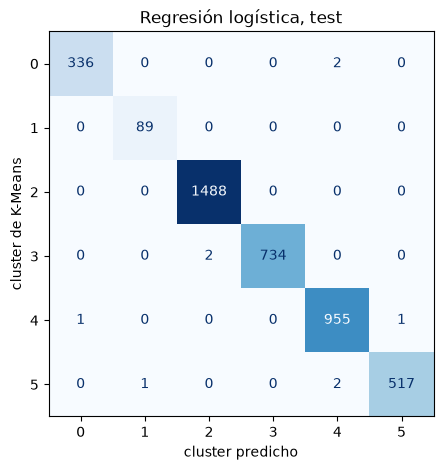

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Regresión logística, test", xlabel="cluster predicho", ylabel="cluster de K-Means")
plt.show()

In [18]:
errors = X_test.loc[pred_test != y_test].assign(predicho=pred_test[pred_test != y_test])
print(f"{len(errors)} errores de {len(X_test)}")
errors.assign(distancia_centroide=dist_to_centroid(errors).round(3),
              margen=(np.sort(kmeans.transform(errors[FEATURES]), axis=1)[:, 1] - dist_to_centroid(errors)).round(3))

9 errores de 4128


,Latitude,Longitude,MedInc,cluster,predicho,distancia_centroide,margen
9658,37.37,-120.67,1.6607,0,4,1.916,0.037
9790,36.25,-121.84,2.6094,4,0,2.114,0.013
16238,37.98,-121.30,4.1750,5,4,1.514,0.007
16000,37.74,-122.47,4.0846,4,5,1.515,0.001
8499,33.89,-118.29,4.2171,3,2,1.403,0.006
20470,34.27,-118.74,4.1800,3,2,1.638,0.006
2225,36.81,-119.84,7.7062,5,1,3.179,0.627
13052,38.61,-121.30,4.3235,5,4,1.631,0.001
9668,38.53,-119.44,1.5817,0,4,2.722,0.033


La columna `margen` es la diferencia entre la distancia al segundo centroide más cercano y al más cercano. Un margen próximo a cero significa que la casa está casi exactamente sobre la frontera entre dos clusters.

8 de los 9 errores tienen un margen inferior a 0,04: son casas que K-Means coloca casi sobre la frontera entre dos clusters, donde la diferencia entre una etiqueta y otra es mínima. La excepción es la casa con `MedInc` 7,7 cerca de Fresno (margen 0,63). Está en una zona con muy pocos puntos de train, entre el cluster 5 y el 1, y ahí la frontera aprendida por la regresión logística no coincide del todo con la de K-Means.

## Paso 5: guardado de los modelos

Guardamos los dos modelos en `models/` con `joblib`, el formato que recomienda scikit-learn. Para cargarlos hay que usar la misma versión de scikit-learn (fijada en `requirements.txt`). También guardamos train y test con su columna `cluster` en `data/processed/`.

In [19]:
MODELS.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)
joblib.dump(kmeans, MODELS / "kmeans_6_clusters.joblib")
joblib.dump(classifier, MODELS / "cluster_classifier_logreg.joblib")
X_train.to_csv(PROCESSED / "housing_train_clusters.csv", index=False)
X_test.to_csv(PROCESSED / "housing_test_clusters.csv", index=False)

# Comprobamos que los archivos guardados dan las mismas predicciones
km_loaded = joblib.load(MODELS / "kmeans_6_clusters.joblib")
clf_loaded = joblib.load(MODELS / "cluster_classifier_logreg.joblib")
assert np.array_equal(km_loaded.predict(Xte), y_test.to_numpy())
assert np.array_equal(clf_loaded.predict(Xte), pred_test)
for f in sorted(MODELS.glob("*.joblib")):
    print(f.relative_to(ROOT), f"{f.stat().st_size / 1024:.1f} KB")

models/cluster_classifier_logreg.joblib 1.9 KB
models/kmeans_6_clusters.joblib 65.6 KB


## Conclusiones

- Con 6 clusters, K-Means separa California en norte, centro y sur y, dentro del norte y del sur, en ingreso bajo y medio-alto. Las casas de ingresos muy altos forman un grupo propio que mezcla las dos grandes áreas metropolitanas.
- La asignación de casas nuevas (test) es coherente con el entrenamiento: mismo reparto, mismas medias y misma distancia a los centroides.
- Para el modelo supervisado elegimos una regresión logística con poca regularización (`C=10000`). Las fronteras de K-Means son lineales y este modelo también, así que reproduce sus etiquetas con un 99,78 % de accuracy en test (9 errores de 4.128, casi todos sobre la frontera). Supera al random forest (99,54 %), que era el mejor con los parámetros por defecto, y es mucho más simple: 1,9 KB y 24 coeficientes.
- Hay una advertencia: la accuracy tan alta no significa que el clasificador haya descubierto algo nuevo. Aprende una regla que K-Means ya definía. Su utilidad es práctica: asigna un grupo a una casa nueva con un modelo pequeño e interpretable.
- Los dos modelos están en `models/`, y train y test con su columna `cluster` en `data/processed/`.